In [ ]:
import re
from pathlib import Path
import numpy as np
from collections import defaultdict
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sys, os
import seaborn as sns


In [2]:
def parse_run_name(folder_name):
    info = {}
    info["is_mac_dt"] = "mac_dt" in folder_name
    info["is_ergodic"] = "ergodic" in folder_name
    info["gp_policy"] = "gpucb" if "gpucb" in folder_name else "gpmean"

    m = re.search(r"starts(\d+)", folder_name)
    info["starts"] = m.group(1) if m else None

    m = re.search(r"T(\d+)", folder_name)
    info["T"] = int(m.group(1)) if m else None

    return info

In [3]:
def load_run_npz(run_dir):
    npz_path = next(Path(run_dir).glob("run_*.npz"))
    return np.load(npz_path, allow_pickle=True)

In [4]:
def get_method_label(npz):
    keys = set(npz.files)

    # --- planner is the PRIMARY identifier ---
    if "planner" in keys:
        planner = npz["planner"].item()

    elif "stem" in keys:
        # infer from stem (this matches your run() logic exactly)
        stem = npz["stem"].item()
        if "mac_dt" in stem:
            planner = "mac_dt"
        elif "ergodic" in stem:
            planner = "ergodic"
        else:
            raise ValueError(f"Cannot infer planner from stem: {stem}")

    else:
        raise ValueError("Cannot determine planner from npz")

    # --- GP mode (safe default) ---
    gp_mode = npz["gp_mode"].item() if "gp_mode" in keys else None

    # --- method ONLY for ergodic ---
    method = npz["method"].item() if ("method" in keys and planner == "ergodic") else None

    # --- final clean label ---
    if planner == "ergodic":
        label = "ergodic" if method is None else f"ergodic-{method}"
    elif planner == "mac_dt":
        label = "mac-dt"
    else:
        label = planner

    # append GP mode if desired
    if gp_mode is not None:
        label = f"{label}-{gp_mode}"

    return label



In [5]:
def detect_cfg_starts(true_phi_map_time, atol=1e-12):
    T = true_phi_map_time.shape[0]
    starts = [0]
    for t in range(1, T):
        if not np.allclose(true_phi_map_time[t], true_phi_map_time[t-1], atol=atol):
            starts.append(t)
    return np.array(starts, dtype=int)

def cfg_intervals_from_true_phi(true_phi_map_time, T_traj):
    cfg_starts = detect_cfg_starts(true_phi_map_time)
    T_end = min(T_traj, true_phi_map_time.shape[0])

    intervals = []
    for i, t0 in enumerate(cfg_starts):
        t1 = cfg_starts[i+1] if i+1 < len(cfg_starts) else T_end
        intervals.append((i, int(t0), int(min(t1, T_end))))
    return cfg_starts, intervals

In [6]:


def extract_map_id_from_name(run_name):
    """
    Extracts map id like 'v0', 'v1', etc. from run folder name.
    """
    m = re.search(r"_v(\d+)_", run_name)
    if m:
        return f"v{m.group(1)}"
    else:
        return None
    
def extract_start_from_name(run_name):
    """
    
    """
    m = re.search(r"starts(\d+)", run_name)
    if m:
        return f"{m.group(1)}"
    else:
        return None
    


sys.path.append(os.path.abspath(".."))
sys.path.append(os.getcwd())
from env.grid import make_env_from_json
def recover_state_index_map(data):
    """
    Recover state_index_map for legacy runs that did not save it.
    """
    # Case 1: already present (new runs)
    if "state_index_map" in data:
        sim = data["state_index_map"]
        # np.load returns object arrays sometimes
        return sim.item() if hasattr(sim, "item") else sim

    # Case 2: reconstruct from env_source

    env_source = data.get("env_source", None)
    
    
    if env_source is None:
        raise RuntimeError("Cannot recover state_index_map: env_source missing")
    
    if isinstance(env_source, np.ndarray):
        env_source = env_source.item()
        print("env_source:", env_source)

    # Rebuild environment exactly as in the run
    if data["env_dyn"] == "dynamic":
        # env_source is a folder → first config defines indexing
        import glob
        json_files = sorted(glob.glob(os.path.join(env_source, "*.json")))
        if not json_files:
            raise RuntimeError(f"No JSON files found in {env_source}")
        env = make_env_from_json(json_files[0])
    else:
        env = make_env_from_json(env_source)

    # Force indexing (exact same logic as simulation)
    env._indexing()
    env._precompute_graph()

    return env._state_index_map

In [7]:
def reshape_traj_by_time(traj_rc_all, n_agents):
    traj = np.asarray(traj_rc_all)
    assert traj.shape[0] % n_agents == 0
    T_env = traj.shape[0] // n_agents
    return traj.reshape(T_env, n_agents, 2)


def first_time_cover_cellset_per_cfg(traj_rc_all, cellset, n_agents, t0, t1):
    traj_t = reshape_traj_by_time(traj_rc_all, n_agents)

    visited = set()
    for t in range(t0, min(t1, traj_t.shape[0])):
        for a in range(n_agents):
            r, c = traj_t[t, a]
            visited.add((int(r), int(c)))
        if visited.issuperset(cellset):
            return t - t0
    return np.nan


def first_time_cover_static(traj_rc_all, cellset, n_agents):
    traj_t = reshape_traj_by_time(traj_rc_all, n_agents)

    visited = set()
    for t in range(traj_t.shape[0]):
        for a in range(n_agents):
            r, c = traj_t[t, a]
            visited.add((int(r), int(c)))
        if visited.issuperset(cellset):
            return t   
    return np.nan


def full_map_cellset_from_state_index_map(state_index_map):
    # keys are (r,c) free cells
    return set((int(r), int(c)) for (r, c) in state_index_map.keys())

In [8]:
def first_time_cover_cellset_from_traj(traj_t, cellset, t0=0, t1=None):
    """
    traj_t: (T_env, n_agents, 2)
    """
    if t1 is None:
        t1 = traj_t.shape[0]

    visited = set()
    for t in range(t0, min(t1, traj_t.shape[0])):
        for a in range(traj_t.shape[1]):
            r, c = traj_t[t, a]
            visited.add((int(r), int(c)))
        if visited.issuperset(cellset):
            return t - t0
    return np.nan

def roi_cover_times_static(traj_rc_all, roi_sets, n_agents):
    traj_t = reshape_traj_by_time(traj_rc_all, n_agents)
    rows = []

    for roi_name, cellset in roi_sets.items():
        t = first_time_cover_cellset_from_traj(traj_t, cellset)
        rows.append({
            "roi": roi_name,
            "visit_time": t,
            "cfg": 0,
        })
    return rows


def roi_cover_times_dynamic(traj_rc_all, roi_sets, n_agents, true_phi_map_time):
    traj_t = reshape_traj_by_time(traj_rc_all, n_agents)
    cfg_starts = detect_cfg_starts(true_phi_map_time)

    rows = []
    for i, t0 in enumerate(cfg_starts):
        t1 = cfg_starts[i+1] if i+1 < len(cfg_starts) else traj_t.shape[0]

        for roi_name, cellset in roi_sets.items():
            t = first_time_cover_cellset_from_traj(traj_t, cellset, t0, t1)
            rows.append({
                "roi": roi_name,
                "cfg": i,
                "visit_time": t,
            })
    return rows

def build_roi_cellsets(roi_rc, roi_name):
    """
    Returns dict: roi_name -> set of (r,c)
    """
    roi_sets = {}
    for (r, c), name in zip(roi_rc, roi_name):
        name = str(name)
        roi_sets.setdefault(name, set()).add((int(r), int(c)))
    return roi_sets

def roi_cover_times_static(traj_rc_all, roi_sets, n_agents):
    traj_t = reshape_traj_by_time(traj_rc_all, n_agents)
    rows = []

    for roi_name, cellset in roi_sets.items():
        t = first_time_cover_cellset_from_traj(traj_t, cellset)
        rows.append({
            "roi": roi_name,
            "visit_time": t,
            "cfg": 0,
        })
    return rows


### Analysis of different Algorithms

In [ ]:
BATCH_DIR = Path("/home/gaby/Documents/UCB/AAM/GIT/sastryrepo/MarkovErgodic/MAES/results/plannerComparison10x10Grid")
for run_dir in list(BATCH_DIR.iterdir()):
    npz = load_run_npz(run_dir)
    print(run_dir.name, "→", get_method_label(npz))
print(len(list(BATCH_DIR.iterdir())))

In [ ]:
map_rows = []

for run_dir in BATCH_DIR.iterdir():
    if not run_dir.is_dir():
        continue

    npz = load_run_npz(run_dir)

    label = get_method_label(npz)
    map_id = extract_map_id_from_name(run_dir.name)
    agent_starts = extract_start_from_name(run_dir.name)
    n_agents = int(npz["n_agents"])

    traj_rc_all = npz["traj_rc_all"]
    true_phi_map_time = npz["true_phi_map_time"]
    state_index_map = recover_state_index_map(npz)

    full_cellset = set((int(r), int(c)) for (r, c) in state_index_map.keys())

    # correct environment time
    T_env = traj_rc_all.shape[0] // n_agents

    # cfg starts (works for static + dynamic)
    cfg_starts = detect_cfg_starts(true_phi_map_time)

    for i, t0 in enumerate(cfg_starts):
        t1 = cfg_starts[i + 1] if i + 1 < len(cfg_starts) else T_env
        t1 = min(t1, T_env)

        cover_t = first_time_cover_cellset_per_cfg(
            traj_rc_all=traj_rc_all,
            cellset=full_cellset,
            n_agents=n_agents,
            t0=t0,
            t1=t1,
        )

        map_rows.append({
            "run": run_dir.name,
            "map_id": map_id,
            "algorithm": label,
            "n_agents": n_agents,
            "agent_starts": agent_starts,
            "cfg": i,
            "full_map_cover_time": cover_t,
            "T_cfg": t1 - t0,
        })

map_df = (
    pd.DataFrame(map_rows)
    .sort_values(["map_id", "algorithm", "n_agents", "agent_starts", "cfg"])
    .reset_index(drop=True)
)

display(map_df)




In [ ]:
cover_df = map_df
cover_summary = (
    cover_df
    .groupby("algorithm", as_index=False)
    .agg(
        mean_cover_time=("full_map_cover_time", "mean"),
        std_cover_time=("full_map_cover_time", "std"),
        success_rate=("full_map_cover_time", lambda x: x.notna().mean()),
        n_runs=("full_map_cover_time", "count"),
    )
)

cover_summary

In [ ]:
roi_rows = []

for run_dir in BATCH_DIR.iterdir():
    if not run_dir.is_dir():
        continue

    npz = load_run_npz(run_dir)

    label = get_method_label(npz)
    map_id = extract_map_id_from_name(run_dir.name)
    agent_starts = extract_start_from_name(run_dir.name)
    n_agents = int(npz["n_agents"])
    env_dyn = str(npz["env_dyn"])

    traj_rc_all = npz["traj_rc_all"]
    true_phi_map_time = npz["true_phi_map_time"]

    roi_sets = build_roi_cellsets(npz["roi_rc"], npz["roi_name"])

    if env_dyn == "static":
        rows = roi_cover_times_static(traj_rc_all, roi_sets, n_agents)
    else:
        rows = roi_cover_times_dynamic(
            traj_rc_all, roi_sets, n_agents, true_phi_map_time
        )

    for r in rows:
        roi_rows.append({
            **r,
            "run": run_dir.name,
            "map_id": map_id,
            "algorithm": label,
            "n_agents": n_agents,
            "agent_starts": agent_starts,
        })

roi_df = pd.DataFrame(roi_rows)
roi_df = roi_df.sort_values(
    ["map_id", "algorithm", "n_agents", "cfg","roi"]
).reset_index(drop=True)

display(roi_df)


In [ ]:
roi_df = roi_df

roi_summary = (
    roi_df
    .groupby(["algorithm", "roi"], as_index=False)
    .agg(
        mean_visit_time=("visit_time", "mean"),
        std_visit_time=("visit_time", "std"),
        n_runs=("visit_time", "count"),
    )
)

roi_summary

In [ ]:
def compute_three_errors_from_series(
    emp_series,
    phi_hat_series,      # \hat{\phi}(t)  -> use npz["phi_norm_series"]
    true_phi_series,     # \phi^*(t)      -> use npz["true_phi_map_time"]
    stride=1,
):
    def _normalize(v):
        v = np.clip(np.asarray(v, dtype=float), 0.0, None)
        s = v.sum()
        return v / s if s > 0 else v

    T = min(len(emp_series), len(phi_hat_series), len(true_phi_series))
    xs = np.arange(0, T, stride)

    err_emp_true, err_emp_belief, err_bel_true = [], [], []

    for t in xs:
        rhat = _normalize(emp_series[t])
        phat = _normalize(phi_hat_series[t])
        ptru = _normalize(true_phi_series[t])

        err_emp_true.append(np.linalg.norm(rhat - ptru, ord=1))
        err_emp_belief.append(np.linalg.norm(rhat - phat, ord=1))
        err_bel_true.append(np.linalg.norm(phat - ptru, ord=1))

    return (
        xs,
        np.array(err_emp_true),
        np.array(err_emp_belief),
        np.array(err_bel_true),
    )



In [ ]:
curves_emp_true   = defaultdict(list)
curves_emp_belief = defaultdict(list)
curves_bel_true   = defaultdict(list)

for run_dir in BATCH_DIR.iterdir():
    if not run_dir.is_dir():
        continue

    npz = load_run_npz(run_dir)
    label = get_method_label(npz)

    x, e_et, e_eb, e_bt = compute_three_errors_from_series(
        emp_series=npz["emp_series"],
        phi_hat_series=npz["phi_norm_series"],
        true_phi_series=npz["true_phi_map_time"],
        stride=1,
    )

    curves_emp_true[label].append(e_et)
    curves_emp_belief[label].append(e_eb)
    curves_bel_true[label].append(e_bt)

In [ ]:
from matplotlib.lines import Line2D
# these are IEEE plot settings
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["DejaVu Sans"],
    "mathtext.fontset": "cm",
    "font.size": 12,
    "axes.labelsize": 13,
    "axes.titlesize": 14,
    "legend.fontsize": 11,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "lines.linewidth": 2.4,
})


fig, ax = plt.subplots(figsize=(8.0, 4.8))  # width > height, clean

# Colorblind-safe palette (Okabe–Ito inspired)
# color_map = {
#     "ergodic-remc-ucb": "#0072B2",  # blue
#     "mac-dt-ucb":       "#D55E00",  # vermillion
# }
# color_map = {
#     "ergodic-remc-ucb": "#6B8EC1",
#     "mac-dt-ucb":         "#E3A26E",
# }
color_map = {
    "ergodic-remc-ucb": "#4C72B0",  # muted blue
    "mac-dt-ucb":         "#DD8452",  # muted orange
}

# Line styles encode metric
metric_styles = {
    "emp_true": dict(linestyle="-",  alpha=0.12),
    "bel_true": dict(linestyle="--", alpha=0.12),
}


method_name_map = {
    "ergodic-remc-ucb": "MA-Ergodic",
    "mac-dt-ucb": "MAC-DT",
}
# ----------------------------
# Plot curves
# ----------------------------
for label in curves_emp_true.keys():

    c = color_map[label]

    # --- Empirical − True (solid) ---
    Ys = curves_emp_true[label]
    min_len = min(len(y) for y in Ys)
    Y = np.stack([y[:min_len] for y in Ys])

    mean = Y.mean(axis=0)
    std  = Y.std(axis=0)
    x = np.arange(min_len)

    ax.plot(
        x, mean,
        color=c,
        linestyle="-",
        label=method_name_map[label]
    )
    ax.fill_between(
        x, mean - std, mean + std,
        color=c,
        alpha=metric_styles["emp_true"]["alpha"],
        linewidth=0
    )

    # --- Belief − True (dashed) ---
    Ys = curves_bel_true[label]
    min_len = min(len(y) for y in Ys)
    Y = np.stack([y[:min_len] for y in Ys])

    mean = Y.mean(axis=0)
    std  = Y.std(axis=0)
    x = np.arange(min_len)

    ax.plot(
        x, mean,
        color=c,
        linestyle="--"
    )
    ax.fill_between(
        x, mean - std, mean + std,
        color=c,
        alpha=metric_styles["bel_true"]["alpha"],
        linewidth=0
    )

# ----------------------------
# Axes, grid, labels
# ----------------------------
ax.set_xlabel("Time step")
ax.set_ylabel(r"$\ell_1$ error")

ax.grid(
    True,
    which="major",
    axis="y",
    alpha=0.25,
    linewidth=0.8
)


ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)


method_handles = [
    Line2D([0], [0], color=color_map["ergodic-remc-ucb"], lw=2.0, label="MA-Ergodic"),
    Line2D([0], [0], color=color_map["mac-dt-ucb"], lw=2.0, label="MAC-DT"),
]

metric_handles = [
    Line2D([0], [0], color="black", lw=2.0, linestyle="-",
           label=r"$\|\hat{\rho} - \bar{\rho}\|_1$ (empirical vs belief)"),
    Line2D([0], [0], color="black", lw=1.5, linestyle="--",
           label=r"$\|\hat{\rho} - \bar{\rho^\star}\|_1$ (belief vs true)"),
]

# legend_lines = [
#     plt.Line2D([0], [0], color="black", linestyle="-",  linewidth=2.4),
#     plt.Line2D([0], [0], color="black", linestyle="--", linewidth=2.4),
# ]

# legend_labels = [
#     r"$\|\hat r - \phi^{\star}\|_1$ (empirical vs true)",
#     r"$\|\hat\phi - \phi^{\star}\|_1$ (belief vs true)",
# ]

leg1 = ax.legend(handles=method_handles, title="Method",
                 loc="upper right", frameon=False)
leg2 = ax.legend(handles=metric_handles, title="Metric",
                 loc="upper center", frameon=False)


ax.add_artist(leg1)

plt.tight_layout()
plt.show()

In [ ]:
# ## To cehck the beleifs of each agents - not fully 
npz = load_run_npz("/home/gaby/Documents/UCB/AAM/GIT/sastryrepo/MarkovErgodic/MAES/results/T300_ergodic_GPupdate25_remc_Pupdate25_v0_gpucb_static_3_starts313131_commModelocal_comm_radius10.0_concenIter5")
phi = npz["phi_agents_time"]   # (T, A, S)
print(phi.shape)
align = np.linalg.norm(phi[:,0,:] - phi[:,1,:], axis=1)
var_phi = np.var(phi, axis=1)  # (T, S)
print(var_phi.shape)
obs = npz["obs_count_agents"]
print(obs.shape)
agent_maps = obs.sum(axis=0)   # (A, S)
print(agent_maps)

### Analysis of communication radius effect in Ergodic 

In [9]:
BATCH_DIR = Path("/home/gaby/Documents/UCB/AAM/GIT/sastryrepo/MarkovErgodic/MAES/results/AnalysisCommRadious_v2")
for run_dir in list(BATCH_DIR.iterdir()):
    npz = load_run_npz(run_dir)
    print(run_dir.name, "→", get_method_label(npz))
print(len(list(BATCH_DIR.iterdir())))

T1000_ergodic_GPupdate25_remc_Pupdate25_v1_gpucb_static_3_starts494949_commModelocal_comm_radius20.0_concenIter5 → ergodic-remc-ucb
T1000_ergodic_GPupdate25_remc_Pupdate25_v3_gpucb_static_6_starts545454545454_commModelocal_comm_radius5.0_concenIter5 → ergodic-remc-ucb
T1000_ergodic_GPupdate25_remc_Pupdate25_v3_gpucb_static_10_starts91919191919191919191_commModelocal_comm_radius5.0_concenIter5 → ergodic-remc-ucb
T1000_ergodic_GPupdate25_remc_Pupdate25_v1_gpucb_static_3_starts494949_commModelocal_comm_radius2.0_concenIter5 → ergodic-remc-ucb
T1000_ergodic_GPupdate25_remc_Pupdate25_v3_gpucb_static_6_starts909090909090_commModelocal_comm_radius2.0_concenIter5 → ergodic-remc-ucb
T1000_ergodic_GPupdate25_remc_Pupdate25_v3_gpucb_static_6_starts070707070707_commModelocal_comm_radius20.0_concenIter5 → ergodic-remc-ucb
T1000_ergodic_GPupdate25_remc_Pupdate25_v3_gpucb_static_10_starts66666666666666666666_commModelocal_comm_radius20.0_concenIter5 → ergodic-remc-ucb
T1000_ergodic_GPupdate25_remc_Pu

In [14]:
roi_rows = []

for run_dir in BATCH_DIR.iterdir():
    if not run_dir.is_dir():
        continue

    npz = load_run_npz(run_dir)

    traj_rc_all = npz["traj_rc_all"]
    true_phi_map_time = npz["true_phi_map_time"]
    env_dyn = str(npz["env_dyn"])

    map_id = extract_map_id_from_name(run_dir.name)
    n_agents = int(npz["n_agents"])
    comm_radius = npz["comm_radius"].item()
    agent_starts = extract_start_from_name(run_dir.name)

    roi_sets = build_roi_cellsets(
        npz["roi_rc"],
        npz["roi_name"]
    )

    if env_dyn == "static":
        rows = roi_cover_times_static(
            traj_rc_all,
            roi_sets,
            n_agents
        )
    else:
        rows = roi_cover_times_dynamic(
            traj_rc_all,
            roi_sets,
            n_agents,
            true_phi_map_time
        )

    for r in rows:
        roi_rows.append({
            "run": run_dir.name,
            "map_id": map_id,
            "roi_name": r["roi"],
            "cfg": r["cfg"],
            "roi_cover_time": r["visit_time"],
            "comm_radius": comm_radius,
            "n_agents": n_agents,
            "agent_starts": agent_starts,
        })

roi_df = pd.DataFrame(roi_rows)

from IPython.display import display
display(roi_df)



,run,map_id,roi_name,cfg,roi_cover_time,comm_radius,n_agents,agent_starts
0,T1000_ergodic_GPupdate25_remc_Pupdate25_v1_gpu...,v1,roi1,0,38,20.0,3,494949
1,T1000_ergodic_GPupdate25_remc_Pupdate25_v1_gpu...,v1,roi2,0,74,20.0,3,494949
2,T1000_ergodic_GPupdate25_remc_Pupdate25_v1_gpu...,v1,roi3,0,146,20.0,3,494949
3,T1000_ergodic_GPupdate25_remc_Pupdate25_v3_gpu...,v3,roi1,0,185,5.0,6,545454545454
4,T1000_ergodic_GPupdate25_remc_Pupdate25_v3_gpu...,v3,roi2,0,61,5.0,6,545454545454
5,T1000_ergodic_GPupdate25_remc_Pupdate25_v3_gpu...,v3,roi3,0,8,5.0,6,545454545454
6,T1000_ergodic_GPupdate25_remc_Pupdate25_v3_gpu...,v3,roi4,0,0,5.0,6,545454545454
7,T1000_ergodic_GPupdate25_remc_Pupdate25_v3_gpu...,v3,roi5,0,45,5.0,6,545454545454
8,T1000_ergodic_GPupdate25_remc_Pupdate25_v3_gpu...,v3,roi1,0,52,5.0,10,91919191919191919191
9,T1000_ergodic_GPupdate25_remc_Pupdate25_v3_gpu...,v3,roi2,0,92,5.0,10,91919191919191919191


In [25]:

# roi_summary = (
#     roi_df
#     .groupby(["comm_radius", "roi_name"], as_index=False) #averaging over
#     .agg(
#         mean_cover_time=("roi_cover_time", "mean"),
#         std_cover_time=("roi_cover_time", "std"),
#         n_runs=("roi_cover_time", "count"),
#     ) 
# )

roi_summary = (
    roi_df
    .groupby(["n_agents", "comm_radius"], as_index=False) #averaging over
    .agg(
        mean_cover_time=("roi_cover_time", "mean"),
        std_cover_time=("roi_cover_time", "std"),
        n_runs=("roi_cover_time", "count"),
    ) 
)


# roi_summary_median = (
#     roi_df
#     .groupby(["n_agents", "comm_radius", "roi_name"], as_index=False)
#     .agg(
#         median_cover_time=("roi_cover_time", "median"),
#         iqr_cover_time=("roi_cover_time", lambda x: x.quantile(0.75) - x.quantile(0.25)),
#     )
# )
roi_df["roi_cover_time_norm"] = (
    roi_df["roi_cover_time"]
    / roi_df.groupby(["map_id", "roi_name"])["roi_cover_time"].transform("median")
)

roi_summary_norm = (
    roi_df
    .groupby(["n_agents", "comm_radius"], as_index=False)
    .agg(
        mean_norm_time=("roi_cover_time_norm", "mean"),
        std_norm_time=("roi_cover_time_norm", "std"),
    )
)

display(roi_summary)

,n_agents,comm_radius,mean_cover_time,std_cover_time,n_runs
0,3,2.0,68.333333,86.509344,6
1,3,5.0,44.333333,33.470385,6
2,3,20.0,53.833333,50.929036,6
3,6,2.0,38.466667,39.547199,15
4,6,5.0,57.400000,77.681401,15
5,6,20.0,55.933333,70.463229,15
6,10,2.0,39.400000,38.104743,15
7,10,5.0,33.533333,27.419666,15
8,10,20.0,30.400000,21.940830,15


In [26]:
display(roi_summary_norm)

,n_agents,comm_radius,mean_norm_time,std_norm_time
0,3,2.0,1.889711,2.260698
1,3,5.0,1.254386,0.910027
2,3,20.0,1.612518,1.558768
3,6,2.0,1.068604,0.874988
4,6,5.0,1.471893,1.657683
5,6,20.0,1.416280,1.361667
6,10,2.0,1.065540,0.744715
7,10,5.0,0.953990,0.601094
8,10,20.0,0.884841,0.504140


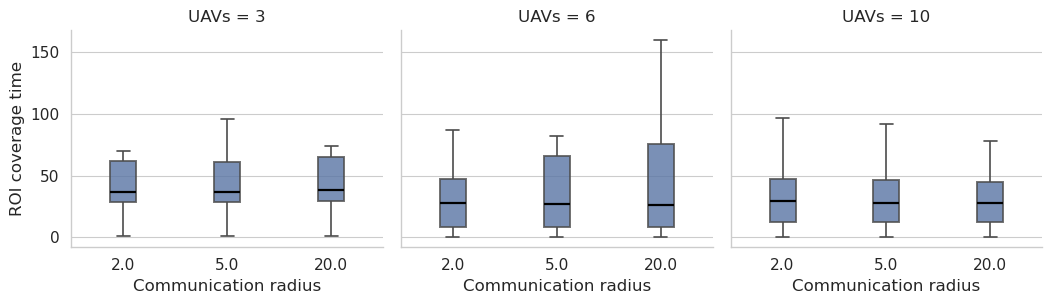

In [31]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(
    style="whitegrid",
    context="paper",
    font_scale=1.25   # ⬅ bigger fonts without changing layout
)

g = sns.catplot(
    data=roi_df,
    x="comm_radius",
    y="roi_cover_time",
    col="n_agents",
    kind="box",
    showfliers=False,
    height=3.2,       # ⬅ shorter
    aspect=1.1,       # ⬅ wider
    width=0.25,
    color="#4C72B0",  # single color
    linewidth=1.4,
    boxprops=dict(alpha=0.8),
    whiskerprops=dict(linewidth=1.2),
    capprops=dict(linewidth=1.2),
    medianprops=dict(color="black", linewidth=1.6),
)

g.set_axis_labels(
    "Communication radius",
    "ROI coverage time"
)

g.set_titles("UAVs = {col_name}")

# Clean spines (IEEE style)
for ax in g.axes.flat:
    sns.despine(ax=ax)

plt.tight_layout()
plt.show()




In [33]:
cover_rows = []

for run_dir in BATCH_DIR.iterdir():
    if not run_dir.is_dir():
        continue

    npz = load_run_npz(run_dir)

    traj_rc_all = npz["traj_rc_all"]
    true_phi_map_time = npz["true_phi_map_time"]
    env_dyn = str(npz["env_dyn"])

    n_agents = int(npz["n_agents"])
    comm_radius = npz["comm_radius"].item()
    map_id = extract_map_id_from_name(run_dir.name)
    agent_starts = extract_start_from_name(run_dir.name)

    # full map cell set (ground truth)
    state_index_map = recover_state_index_map(npz)
    full_cellset = set((int(r), int(c)) for (r, c) in state_index_map.keys())

    traj_t = reshape_traj_by_time(traj_rc_all, n_agents)

    if env_dyn == "static":
        cover_t = first_time_cover_cellset_from_traj(
            traj_t,
            full_cellset
        )

        cover_rows.append({
            "run": run_dir.name,
            "map_id": map_id,
            "n_agents": n_agents,
            "comm_radius": comm_radius,
            "cfg": 0,
            "cover_time": cover_t,
            "agent_starts": agent_starts,
        })

    else:
        cfg_starts = detect_cfg_starts(true_phi_map_time)

        for i, t0 in enumerate(cfg_starts):
            t1 = cfg_starts[i+1] if i+1 < len(cfg_starts) else traj_t.shape[0]

            cover_t = first_time_cover_cellset_from_traj(
                traj_t,
                full_cellset,
                t0=t0,
                t1=t1
            )

            cover_rows.append({
                "run": run_dir.name,
                "map_id": map_id,
                "n_agents": n_agents,
                "comm_radius": comm_radius,
                "cfg": i,
                "cover_time": cover_t,
                "agent_starts": agent_starts,
            })

cover_df = pd.DataFrame(cover_rows)

from IPython.display import display
display(cover_df)


,run,map_id,n_agents,comm_radius,cfg,cover_time,agent_starts
0,T1000_ergodic_GPupdate25_remc_Pupdate25_v1_gpu...,v1,3,20.0,0,928,494949
1,T1000_ergodic_GPupdate25_remc_Pupdate25_v3_gpu...,v3,6,5.0,0,228,545454545454
2,T1000_ergodic_GPupdate25_remc_Pupdate25_v3_gpu...,v3,10,5.0,0,115,91919191919191919191
3,T1000_ergodic_GPupdate25_remc_Pupdate25_v1_gpu...,v1,3,2.0,0,502,494949
4,T1000_ergodic_GPupdate25_remc_Pupdate25_v3_gpu...,v3,6,2.0,0,160,909090909090
5,T1000_ergodic_GPupdate25_remc_Pupdate25_v3_gpu...,v3,6,20.0,0,432,070707070707
6,T1000_ergodic_GPupdate25_remc_Pupdate25_v3_gpu...,v3,10,20.0,0,72,66666666666666666666
7,T1000_ergodic_GPupdate25_remc_Pupdate25_v3_gpu...,v3,6,5.0,0,223,070707070707
8,T1000_ergodic_GPupdate25_remc_Pupdate25_v1_gpu...,v1,3,5.0,0,267,494949
9,T1000_ergodic_GPupdate25_remc_Pupdate25_v3_gpu...,v3,10,20.0,0,119,91919191919191919191


In [34]:
cover_df["covered"] = cover_df["cover_time"].notna()

cover_summary = (
    cover_df
    .groupby(["n_agents", "comm_radius"], as_index=False)
    .agg(
        n_runs=("cover_time", "count"),
        success_rate=("covered", "mean"),
        mean_cover_time=("cover_time", "mean"),
        std_cover_time=("cover_time", "std"),
    )
)

cover_summary

,n_agents,comm_radius,n_runs,success_rate,mean_cover_time,std_cover_time
0,3,2.0,2,1.0,363.500000,195.868578
1,3,5.0,2,1.0,304.000000,52.325902
2,3,20.0,2,1.0,707.500000,311.834091
3,6,2.0,3,1.0,229.666667,101.401841
4,6,5.0,3,1.0,262.333333,63.846169
5,6,20.0,3,1.0,312.000000,103.966341
6,10,2.0,3,1.0,127.333333,15.821926
7,10,5.0,3,1.0,112.666667,21.594752
8,10,20.0,3,1.0,150.000000,97.277952


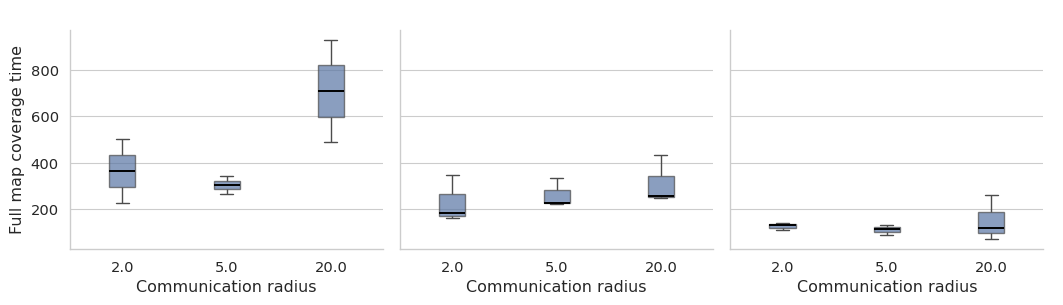

In [44]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(
    style="whitegrid",
    context="paper",
    font_scale=1.2,   
)

g = sns.catplot(
    data=cover_df,
    x="comm_radius",
    y="cover_time",
    col="n_agents",
    kind="box",
    showfliers=False,
    height=3.2,        
    aspect=1.1,
    width=0.25,
    color="#4C72B0",  
    linewidth=1.0,
    boxprops=dict(alpha=0.7),
    whiskerprops=dict(linewidth=1.0),
    capprops=dict(linewidth=1.0),
    medianprops=dict(color="black", linewidth=1.4),
)

g.set_axis_labels(
    "Communication radius",
    "Full map coverage time"
)

# g.set_titles("UAVs = {col_name}")
g.set_titles(" ")

# Clean spines
for ax in g.axes.flat:
    sns.despine(ax=ax)

plt.tight_layout()
plt.savefig("full_map_coverage_vs_comm_radius.pdf", bbox_inches="tight")
plt.show()




### KL Divergence

In [ ]:
BATCH_DIR = Path("/home/gaby/Documents/UCB/AAM/GIT/sastryrepo/MarkovErgodic/MAES/results/AnalysisCommRadious_v2")
for run_dir in list(BATCH_DIR.iterdir()):
    npz = load_run_npz(run_dir)
    print(run_dir.name, "→", get_method_label(npz))
print(len(list(BATCH_DIR.iterdir())))

In [ ]:
def kl_divergence(p, q, eps=1e-12):
    p = np.clip(p, eps, None)
    q = np.clip(q, eps, None)
    return np.sum(p * np.log(p / q))

In [ ]:
rows = []

for run_dir in BATCH_DIR.iterdir():
    if not run_dir.is_dir():
        continue

    npz = load_run_npz(run_dir)

    n_agents = int(npz["n_agents"])
    comm_radius = float(npz["comm_radius"])

    phi_agents_time = npz["phi_agents_time"]   # (T, n_agents, nstates)
    gp_update_steps = npz["gp_update_steps"]   # (n_updates,)

    for t in gp_update_steps:
        phis = phi_agents_time[t]  # (n_agents, nstates)

        # normalize defensively
        phis = phis / phis.sum(axis=1, keepdims=True)

        phi_mean = phis.mean(axis=0)

        kl_vals = [
            kl_divergence(phis[a], phi_mean)
            for a in range(n_agents)
        ]

        rows.append({
            "time": int(t),
            "kl_mean": float(np.mean(kl_vals)),
            "kl_std": float(np.std(kl_vals)),
            "n_agents": n_agents,
            "comm_radius": comm_radius,
            "run": run_dir.name,
        })

kl_df = pd.DataFrame(rows)


In [ ]:
import matplotlib as mpl
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid")

mpl.rcParams.update({
    "figure.dpi": 300,
    "savefig.dpi": 300,

    "axes.labelsize": 12,
    "axes.titlesize": 12,

    "xtick.labelsize": 8,
    "ytick.labelsize": 8,

    "legend.fontsize": 10,
    "font.size": 10,

    "lines.linewidth": 1.2,
})

g = sns.relplot(
    data=kl_df,
    x="time",
    y="kl_mean",
    hue="comm_radius",
    col="n_agents",
    kind="line",
    palette="colorblind",
    height=4,
    aspect=1.0,
    facet_kws=dict(sharey=True, sharex=True),
)

g.set_axis_labels(
    "Timestep",
    "KL divergence to mean belief"
)

g.set_titles("Number of UAVs = {col_name}")

for ax in g.axes.flat:
    sns.despine(ax=ax)

plt.tight_layout()


In [ ]:
rows = []

for run_dir in BATCH_DIR.iterdir():
    if not run_dir.is_dir():
        continue

    npz = load_run_npz(run_dir)

    n_agents = int(npz["n_agents"])
    comm_radius = float(npz["comm_radius"])

    T = int(npz["T"])

    for t in range(T):


        rows.append({
            "time": t,
            # "coverage": frac,
            "n_agents": n_agents,
            "comm_radius": comm_radius,
            "run": run_dir.name,
        })

cov_df = pd.DataFrame(rows)


In [ ]:
cov_df = pd.DataFrame(rows)
g = sns.relplot(
    data=cov_df,
    x="time",
    y="coverage",
    hue="comm_radius",
    col="n_agents",
    kind="line",
    palette="colorblind",
    height=4,
    aspect=1.0,
)


g.set_axis_labels("Timestep", "Fraction of map explored")
# g.set_titles("UAVs = {col_name}")
g.set_titles(" ")

for ax in g.axes.flat:
    ax.set_ylim(0.9, 1.01)   
    sns.despine(ax=ax)

plt.tight_layout()
plt.savefig("fracKL_.png", bbox_inches="tight")
plt.show()


In [ ]:
cov_df_500 = cov_df[cov_df["time"] <= 500]
g = sns.relplot(
    data=cov_df_500,
    x="time",
    y="coverage",
    hue="comm_radius",
    col="n_agents",
    kind="line",
    palette="colorblind",
    height=4,
    aspect=1.0,
)

g.set_axis_labels("Time", "Fraction of map explored")
# g.set_titles("Number of UAVs = {col_name}")
g.set_titles(" ")

for ax in g.axes.flat:
    sns.despine(ax=ax)

plt.tight_layout()


### Analysis P Matrix

In [ ]:
BATCH_DIR = Path("/home/gaby/Documents/UCB/AAM/GIT/sastryrepo/MarkovErgodic/MAES/results/P_GP_update_dyn")
for run_dir in list(BATCH_DIR.iterdir()):
    npz = load_run_npz(run_dir)
    print(run_dir.name, "→", get_method_label(npz))
print(len(list(BATCH_DIR.iterdir())))

In [ ]:
rows = []




debug_rows = []
max_cfg = 0

for run_dir in BATCH_DIR.iterdir():
    if not run_dir.is_dir():
        continue

    npz = load_run_npz(run_dir)

    filename = run_dir.name
    gp_u = int(npz["gp_update"])
    p_u  = int(npz["p_update"])

    traj = npz["traj_rc_all"]  # (T_traj, 2)
    true_phi_map_time = npz["true_phi_map_time"]  # (T_phi, nstates)

    cfg_starts = detect_cfg_starts(true_phi_map_time)
    max_cfg = max(max_cfg, len(cfg_starts))

    roi_rc = npz["roi_rc"]
    roi_name = npz["roi_name"]
    n_agents = npz["n_agents"].item()
    start_agents = extract_start_from_name(run_dir.name)

    # build per-ROI-name cell sets (so you can debug per ROI name)
    roi_cells_by_name = {}
    for (r, c), nm in zip(roi_rc, roi_name):
        nm = str(nm)
        roi_cells_by_name.setdefault(nm, set()).add((int(r), int(c)))

    # define cfg intervals (use cfg_starts; end is next start or min length)
    T_end = min(traj.shape[0], true_phi_map_time.shape[0])
    cfg_intervals = []
    for i, t0 in enumerate(cfg_starts):
        t1 = cfg_starts[i+1] if i+1 < len(cfg_starts) else T_end
        t1 = min(t1, T_end)
        cfg_intervals.append((i, int(t0), int(t1)))

    # compute first-visit time per ROI name per cfg interval
    for nm, cellset in roi_cells_by_name.items():
        row = {
            "filename": filename,
            "num agents": n_agents,
            "gp_update": gp_u,
            "p_update": p_u,
            "roi_name": nm,
            "cfg_starts": cfg_starts.copy(),  # keep for debugging (object col)
            "start_agents": start_agents,
        }

        for (cfg_idx, t0, t1) in cfg_intervals:
            visit = np.nan
            # scan only within this cfg interval
            for t in range(t0, t1):
                r, c = traj[t]
                if (int(r), int(c)) in cellset:
                    visit = t
                    break
            row[f"visit_after_cfg{cfg_idx}"] = visit

        debug_rows.append(row)

debug_df = pd.DataFrame(debug_rows)

# make it easier to read: sort & show key columns
visit_cols = [c for c in debug_df.columns if c.startswith("visit_after_cfg")]
show_cols = ["filename", "num agents", "start_agents", "gp_update", "p_update", "roi_name"] + visit_cols

pd.set_option("display.max_rows", None, "display.max_columns", None, "display.width", None)
# display(debug_df[show_cols])
display(debug_df[show_cols].sort_values(["gp_update", "p_update", "filename", "num agents", "start_agents", "roi_name"]).reset_index(drop=True))

In [ ]:

group_cols = ["num agents", "gp_update", "p_update"]
print("cfg_starts:", cfg_starts)

visit_cols = [c for c in debug_df.columns if c.startswith("visit_after_cfg")]

avg_df = (
    debug_df
    .groupby(group_cols, as_index=False)[visit_cols]
    .mean()
    .sort_values(group_cols)
)


# cfg_starts = detect_cfg_starts(true_phi_map_time)

# map column -> cfg index
def cfg_idx_from_col(col):
    return int(col.replace("visit_after_cfg", ""))

avg_delay_df = avg_df.copy()

for col in visit_cols:
    idx = cfg_idx_from_col(col)
    if idx < len(cfg_starts):
        avg_delay_df[col] = avg_delay_df[col] - cfg_starts[idx]


avg_delay_df = avg_delay_df.rename(
    columns={c: f"delay_cfg{cfg_idx_from_col(c)}" for c in visit_cols}
)

display(avg_delay_df)






In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid", context="paper")

# ---- prepare plotting dataframe ----
delay_cols = [c for c in debug_df.columns if c.startswith("visit_after_cfg")]

plot_df = debug_df.melt(
    id_vars=["num agents", "gp_update", "p_update", "roi_name"],
    value_vars=delay_cols,
    var_name="cfg",
    value_name="visit_time"
)

# extract cfg index ONCE
plot_df["cfg"] = plot_df["cfg"].str.extract(r"cfg(\d+)").astype(int)

# subtract cfg start times
plot_df["delay"] = plot_df["visit_time"] - plot_df["cfg"].map(
    lambda i: cfg_starts[i] if i < len(cfg_starts) else np.nan
)

plot_df = plot_df.dropna(subset=["delay"])

plot_df["update_pair"] = (
    "GP=" + plot_df["gp_update"].astype(str)
    + ", P=" + plot_df["p_update"].astype(str)
)

# ---- plotting: 3 subplots (one per num_agents) ----
agents = sorted(plot_df["num agents"].unique())

fig, axes = plt.subplots(
    1, len(agents),
    figsize=(5.5 * len(agents), 5),
    sharey=True
)

update_order = [
    "GP=10, P=10",
    "GP=25, P=25",
    "GP=50, P=50",
]

if len(agents) == 1:
    axes = [axes]

for ax, n in zip(axes, agents):
    sub = plot_df[plot_df["num agents"] == n]

    sns.boxplot(
        data=sub,
        x="update_pair",
        y="delay",
        hue="cfg",
        order=update_order, 
        showfliers=False,
        width=0.6,
        ax=ax
    )

    ax.set_title(f"Number of agents = {n}", fontsize=18)
    ax.set_xlabel("GP / P update frequency")
    ax.set_ylabel("Steps to reach ROI after map change")

    ax.legend(title="Map change", loc="upper right")

plt.tight_layout()
plt.show()



In [ ]:
from collections import defaultdict

cover_times = defaultdict(list)

for run_dir in BATCH_DIR.iterdir():
    if not run_dir.is_dir():
        continue

    npz = load_run_npz(run_dir)

    n_agents = npz["n_agents"].item()
    gp_u = int(npz["gp_update"])
    p_u  = int(npz["p_update"])

    key = (n_agents, gp_u, p_u)

    cover_t = int(npz["cover_time"])
    if cover_t >= 0:
        cover_times[key].append(cover_t)


mean_cover_time = {
    k: np.mean(v) for k, v in cover_times.items() if len(v) > 0
}
print(cover_times.items())

In [ ]:


curves = defaultdict(lambda: {
    "emp_true": [],
    "bel_true": [],
})

for run_dir in BATCH_DIR.iterdir():
    if not run_dir.is_dir():
        continue

    npz = load_run_npz(run_dir)

    n_agents = npz["n_agents"].item()
    gp_u = int(npz["gp_update"])
    p_u  = int(npz["p_update"])

    key = (n_agents, gp_u, p_u)

    emp_series = npz["emp_series"]
    phi_hat_series = npz["phi_norm_series"]
    true_phi_series = npz["true_phi_map_time"]

    xs, err_emp_true, _, err_bel_true = compute_three_errors_from_series(
        emp_series,
        phi_hat_series,
        true_phi_series,
        stride=1
    )

    curves[key]["emp_true"].append(err_emp_true)
    curves[key]["bel_true"].append(err_bel_true)

In [ ]:
update_color_map = {
    (10, 10): "#4C72B0",  # blue
    (25, 25): "#DD8452",  # orange
    (50, 50): "#55A868",  # green
}

update_label_map = {
    (10, 10): "GP=10, P=10",
    (25, 25): "GP=25, P=25",
    (50, 50): "GP=50, P=50",
}


In [ ]:
from matplotlib.lines import Line2D
import matplotlib.pyplot as plt
import numpy as np

agents = sorted(set(k[0] for k in curves.keys()))

for n in agents:

    fig, ax = plt.subplots(figsize=(10.0, 5.))

    for (na, gp_u, p_u), data in curves.items():
        if na != n:
            continue

        color = update_color_map[(gp_u, p_u)]
        label = update_label_map[(gp_u, p_u)]

        # ---------- empirical vs true ----------
        Ys = data["emp_true"]
        min_len = min(len(y) for y in Ys)
        Y = np.stack([y[:min_len] for y in Ys])

        mean = Y.mean(axis=0)
        std  = Y.std(axis=0)
        x = np.arange(min_len)

        ax.plot(x, mean, color=color, linestyle="-", label=label)
        ax.fill_between(
            x, mean - std, mean + std,
            color=color, alpha=0.12, linewidth=0
        )

        # ---------- belief vs true ----------
        Ys = data["bel_true"]
        min_len = min(len(y) for y in Ys)
        Y = np.stack([y[:min_len] for y in Ys])

        mean = Y.mean(axis=0)
        std  = Y.std(axis=0)

        ax.plot(x, mean, color=color, linestyle="--")
        ax.fill_between(
            x, mean - std, mean + std,
            color=color, alpha=0.12, linewidth=0
        )

        # ---------- vertical line: map fully covered ----------
        if (n, gp_u, p_u) in mean_cover_time:
            ax.axvline(
                mean_cover_time[(n, gp_u, p_u)],
                color=color,
                linestyle=":",
                linewidth=2.0,
                alpha=0.9
            )

    # ---------- axes & styling ----------
    ax.set_title(f"Number of agents = {n}")
    ax.set_xlabel("Time step")
    ax.set_ylabel(r"$\ell_1$ error")

    ax.grid(True, axis="y", alpha=0.25)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    # ---------- legends ----------
    update_handles = [
        Line2D([0], [0], color=update_color_map[(10,10)], lw=2.4, label="GP=10, P=10"),
        Line2D([0], [0], color=update_color_map[(25,25)], lw=2.4, label="GP=25, P=25"),
        Line2D([0], [0], color=update_color_map[(50,50)], lw=2.4, label="GP=50, P=50"),
    ]

    metric_handles = [
        Line2D([0], [0], color="black", lw=2.0, linestyle="-",
               label=r"$\|\hat{\rho}_t - \bar{\rho}_t\|_1$ (empirical vs true)"),
        Line2D([0], [0], color="black", lw=2.0, linestyle="--",
               label=r"$\|\hat{\rho}_t - \rho^\star_t|_1$ (belief vs true)"),
        Line2D([0], [0], color="black", lw=2.0, linestyle=":",
               label="Map fully covered"),
    ]

    leg1 = ax.legend(handles=update_handles, title="GP / P update",
                     loc="upper right", frameon=False)
    leg2 = ax.legend(handles=metric_handles, title="Metric",
                     loc="upper center", frameon=False)
    ax.add_artist(leg1)

    plt.tight_layout()
    plt.show()



In [ ]:


cover_rows = []

for run_dir in BATCH_DIR.iterdir():
    if not run_dir.is_dir():
        continue

    npz = load_run_npz(run_dir)

    cover_rows.append({
        "filename": run_dir.name,
        "num_agents": npz["n_agents"].item(),
        "gp_update": int(npz["gp_update"]),
        "p_update": int(npz["p_update"]),
        "cover_time": int(npz["cover_time"]),
    })

cover_raw_df = pd.DataFrame(cover_rows).sort_values(
    ["num_agents", "gp_update", "p_update", "filename"]
).reset_index(drop=True)

display(cover_raw_df)
